In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("drebin-215-dataset-5560malware-9476-benign.csv")

print("Shape:", df.shape)
df.head()

Shape: (15036, 216)


C:\Users\Admin\AppData\Local\Temp\ipykernel_27552\943835890.py:4: DtypeWarning: Columns (0: TelephonyManager.getSimCountryIso) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("drebin-215-dataset-5560malware-9476-benign.csv")


,transact,onServiceConnected,bindService,attachInterface,ServiceConnection,android.os.Binder,SEND_SMS,Ljava.lang.Class.getCanonicalName,Ljava.lang.Class.getMethods,Ljava.lang.Class.cast,...,READ_CONTACTS,DEVICE_POWER,HARDWARE_TEST,ACCESS_WIFI_STATE,WRITE_EXTERNAL_STORAGE,ACCESS_FINE_LOCATION,SET_WALLPAPER_HINTS,SET_PREFERRED_APPLICATIONS,WRITE_SECURE_SETTINGS,class
0,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,S
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,S
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,S
3,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,1,0,0,0,S
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,S


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15036 entries, 0 to 15035
Columns: 216 entries, transact to class
dtypes: int64(214), object(1), str(1)
memory usage: 24.8+ MB


In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("drebin-215-dataset-5560malware-9476-benign.csv", low_memory=False)

bad_col = "TelephonyManager.getSimCountryIso"
print(df[bad_col].value_counts())
print("\nLabel values:\n", df["class"].value_counts())

TelephonyManager.getSimCountryIso
0    12508
1     2523
?        5
Name: count, dtype: int64

Label values:
 class
B    9476
S    5560
Name: count, dtype: int64


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reload the original data
df = pd.read_csv("drebin-215-dataset-5560malware-9476-benign.csv", low_memory=False)

# Make features numeric; '?' becomes NaN
feature_cols = [c for c in df.columns if c != "class"]
df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")

# Drop only the 5 bad rows (NO drop_duplicates this time)
df = df.dropna()

# Encode the label
df["class"] = df["class"].map({"B": 0, "S": 1})

X = df.drop(columns=["class"])
y = df["class"]

print("X shape:", X.shape)
print("Class balance:\n", y.value_counts())

# Split and scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, "Test:", X_test_scaled.shape)

X shape: (15031, 215)
Class balance:
 class
0    9476
1    5555
Name: count, dtype: int64
Train: (12024, 215) Test: (3007, 215)


In [5]:
# Encode: malware (S) = 1, benign (B) = 0
df["class"] = df["class"].map({"B": 0, "S": 1})

X = df.drop(columns=["class"])
y = df["class"]

print("X shape:", X.shape)
print("Class balance:\n", y.value_counts())
print("Any NaN left?", df.isnull().sum().sum())

X shape: (15031, 215)
Class balance:
 Series([], Name: count, dtype: int64)
Any NaN left? 15031


In [6]:
from sklearn.svm import SVC

svm_linear = SVC(kernel="linear", C=1, class_weight="balanced", random_state=42)
svm_linear.fit(X_train_scaled, y_train)

print("Training done")

Training done


Accuracy: 0.9787

Classification Report:

              precision    recall  f1-score   support

      Benign       0.99      0.98      0.98      1896
     Malware       0.97      0.98      0.97      1111

    accuracy                           0.98      3007
   macro avg       0.98      0.98      0.98      3007
weighted avg       0.98      0.98      0.98      3007



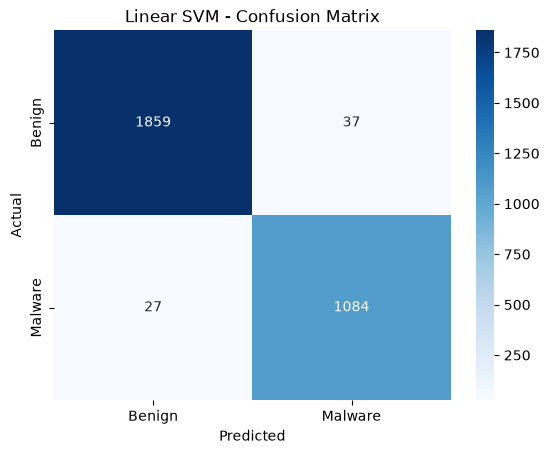

In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = svm_linear.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malware"]))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malware"], yticklabels=["Benign", "Malware"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Linear SVM - Confusion Matrix")
plt.show()